<a href="https://colab.research.google.com/github/batu-uchicago/bayes-applications/blob/main/Bayesian%20Changepoint%20Detection/change_point_detect.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bayesian changepoint detection

A stock's daily returns behave one way for months, and then a shock (a new policy, a crisis) changes how they behave.
Nobody announces the change: we have to infer it from the returns.

The model is the Bayes net of the week 4 slides, one column a day:

- $c_t$, **hidden**: did the regime change today? $P(c_t = 1) = H = 1/250$, about once a year of trading days.
- $\theta_t = (\mu, \sigma)$, **hidden**: the regime. If $c_t = 0$, $\theta_t = \theta_{t-1}$; if $c_t = 1$, a fresh $\theta_t$ is drawn from the prior $p(\theta)$.
- $x_t \sim \mathcal{N}(\mu, \sigma)$, **observed**: the day's return.

Adams and MacKay ([2007](https://arxiv.org/abs/0710.3742)) infer the **run length** $r_t$, the number of days since the last change, one day at a time:

1. **Predict.** For every run length $r$, the posterior predictive of today's return given the last $r$ returns. The prior on $(\mu, \sigma)$ is a Normal-Gamma, conjugate to the Normal, so this predictive is a Student $t$ in closed form.
2. **Grow.** $P(r_t = r_{t-1} + 1) \propto P(r_{t-1}) \times \text{predictive} \times (1 - H)$: no change, the run goes on.
3. **Change.** $P(r_t = 0) \propto \sum_{r_{t-1}} P(r_{t-1}) \times \text{predictive} \times H$: the run restarts.
4. **Update.** Normalize, then update every run's Normal-Gamma posterior with today's return; a new run starts from the prior.

At the end we read the changepoints off backwards: the most probable run length on the last day says when the last regime began, the most probable run length on that day says when the one before it began, and so on.

## 1. Setup

Run the cell below once. On Colab it installs yfinance and downloads the data file.

In [1]:
# On your laptop, `pip install -r requirements.txt` (see the README) has installed everything.
import os, subprocess, sys, urllib.request

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yfinance"], check=True)
    if not os.path.exists("imkb.csv"):
        urllib.request.urlretrieve("https://raw.githubusercontent.com/batu-uchicago/bayes-applications/main/"
                                   "Bayesian%20Changepoint%20Detection/imkb.csv", "imkb.csv")
print("Setup complete.")

Setup complete.


In [2]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import yfinance as yf

## 2. The algorithm

In [3]:
def bocpd(x, hazard=1 / 250, mu0=0.0, kappa0=1.0, alpha0=1.0, beta0=1e-4):
    """Run-length posterior of Bayesian online changepoint detection.

    x are the daily returns. The prior on a regime's mean and precision is Normal-Gamma:
    mu0 and kappa0 for the mean, alpha0 and beta0 for the precision (beta0 / alpha0 is
    the prior's guess of the variance, here a daily standard deviation of 1%).
    Column t + 1 of the result is P(r | x[0], ..., x[t]); row r is the run length.
    """
    T = len(x)
    R = np.zeros((T + 1, T + 1))
    R[0, 0] = 1  # before any data, the run has just started
    # one Normal-Gamma posterior per run length, the prior for run length 0
    mu, kappa, alpha, beta = (np.array([v]) for v in (mu0, kappa0, alpha0, beta0))
    for t in range(T):
        # 1. predict: each run's posterior predictive of x[t] is a Student t
        pred = stats.t.pdf(x[t], df=2 * alpha, loc=mu, scale=np.sqrt(beta * (kappa + 1) / (alpha * kappa)))
        # 2. grow: no change, every run gets one day longer
        R[1:t + 2, t + 1] = R[:t + 1, t] * pred * (1 - hazard)
        # 3. change: the run restarts
        R[0, t + 1] = np.sum(R[:t + 1, t] * pred * hazard)
        # 4. normalize, then update every run with x[t]; a new run starts from the prior
        R[:, t + 1] /= R[:, t + 1].sum()
        mu, kappa, alpha, beta = (np.r_[mu0, (kappa * mu + x[t]) / (kappa + 1)],
                                  np.r_[kappa0, kappa + 1],
                                  np.r_[alpha0, alpha + 0.5],
                                  np.r_[beta0, beta + kappa * (x[t] - mu) ** 2 / (2 * (kappa + 1))])
    return R


def changepoints(R):
    """The regimes' first days: the most probable run length at the end, then at the start of that run, and so on."""
    t, starts = R.shape[1] - 1, []
    while t > 0 and t - R[:, t].argmax() > 0:
        t -= R[:, t].argmax()
        starts.append(t)
    return sorted(starts)

In [4]:
def show(dates, x, R, title):
    """The returns with the changepoints found, the run-length posterior, and a table of the regimes."""
    dates, starts = pd.DatetimeIndex(dates), changepoints(R)
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    top.plot(dates, x, color="#101014", lw=0.8)
    for s in starts:
        top.axvline(dates[s], color="#800000", ls="--", lw=1.5)
    top.set(title=f"{title}: daily returns, and the changepoints found", ylabel="return")
    # darker is more probable; run length 0 at the bottom
    span = [mdates.date2num(dates[0]), mdates.date2num(dates[-1]), 0, R.shape[0]]
    bottom.imshow(-np.log(R[:, 1:] + 1e-7), cmap="gray", vmin=0, vmax=14, aspect="auto", origin="lower", extent=span)
    bottom.plot(dates, R[:, 1:].argmax(0), color="#800000", lw=1.2, label="most probable run length")
    bottom.set(title="Run-length posterior P(r | returns so far): darker is more probable", ylabel="run length (days)")
    bottom.set_ylim(0, 1.3 * R[:, 1:].argmax(0).max() + 10)
    bottom.legend(loc="upper left")
    bottom.xaxis_date()
    plt.tight_layout()
    plt.show()
    edges = [0] + starts + [len(x)]
    return pd.DataFrame({"first day": [dates[a].date() for a in edges[:-1]],
                         "days": np.diff(edges),
                         "mean return": [x[a:b].mean() for a, b in zip(edges[:-1], edges[1:])],
                         "daily std": [x[a:b].std() for a, b in zip(edges[:-1], edges[1:])]}).round(4)

## 3. The Istanbul stock exchange, 2009-2014

The IMKB 100 index of the Istanbul stock exchange (today's BIST 100), from October 2009 to January 2014.
The file has two rows a day; the second is the close.

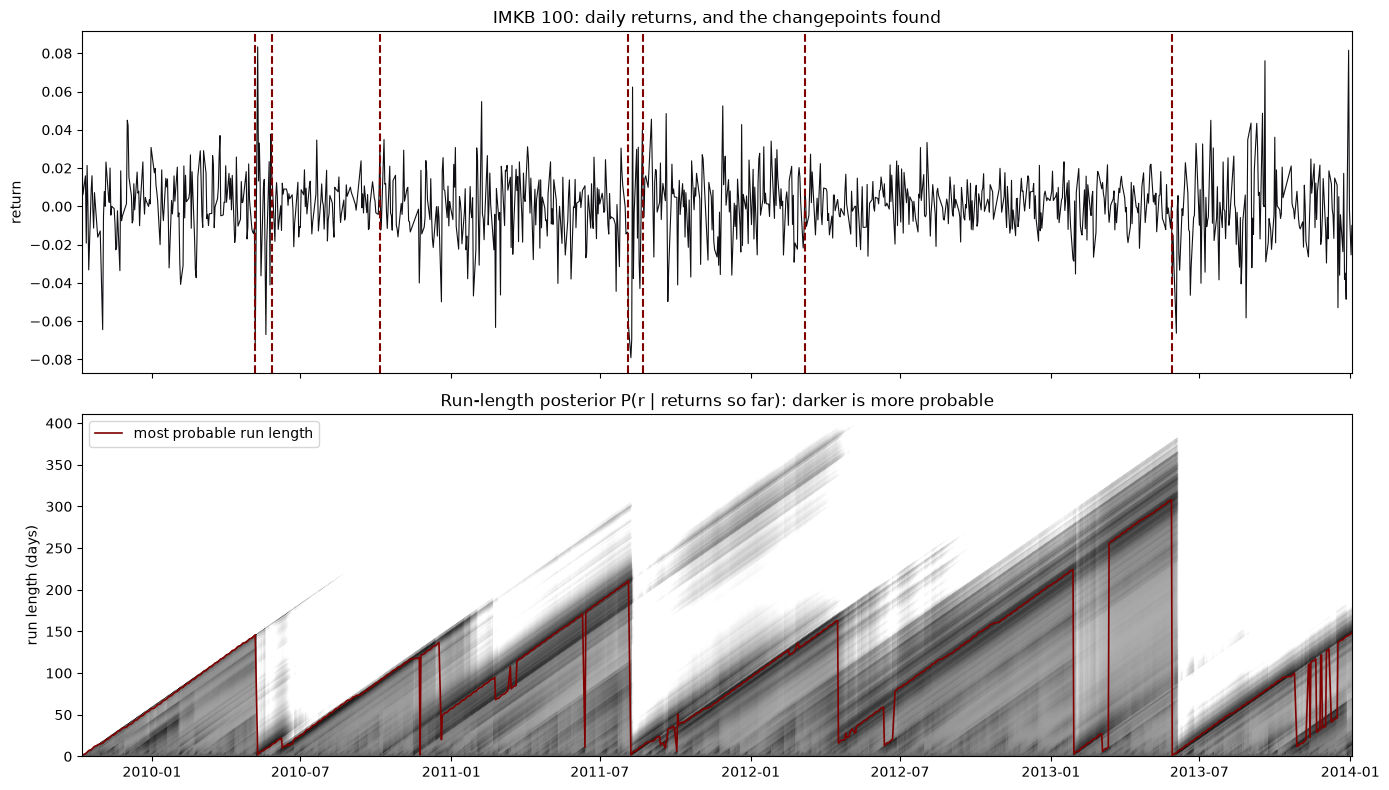

,first day,days,mean return,daily std
0,2009-10-08,145,0.0017,0.0168
1,2010-05-07,13,-0.0007,0.0427
2,2010-05-27,90,0.0020,0.0101
3,2010-10-06,210,-0.0012,0.0172
4,2011-08-05,12,-0.0147,0.0448
5,2011-08-23,134,0.0017,0.0187
6,2012-03-07,308,0.0014,0.0109
7,2013-05-29,148,-0.0033,0.0231


In [5]:
imkb = pd.read_csv("imkb.csv").iloc[1::2]
close = imkb["market"].to_numpy()
x = np.diff(close) / close[:-1]                           # the day's return, dated by its close
dates = pd.to_datetime(imkb["date"], format="%d/%m/%y").to_numpy()[1:]
show(dates, x, bocpd(x), "IMKB 100")

## 4. An energy fund, 2024-2026

XLE, the Energy Select Sector SPDR fund, from Yahoo Finance, with log returns.

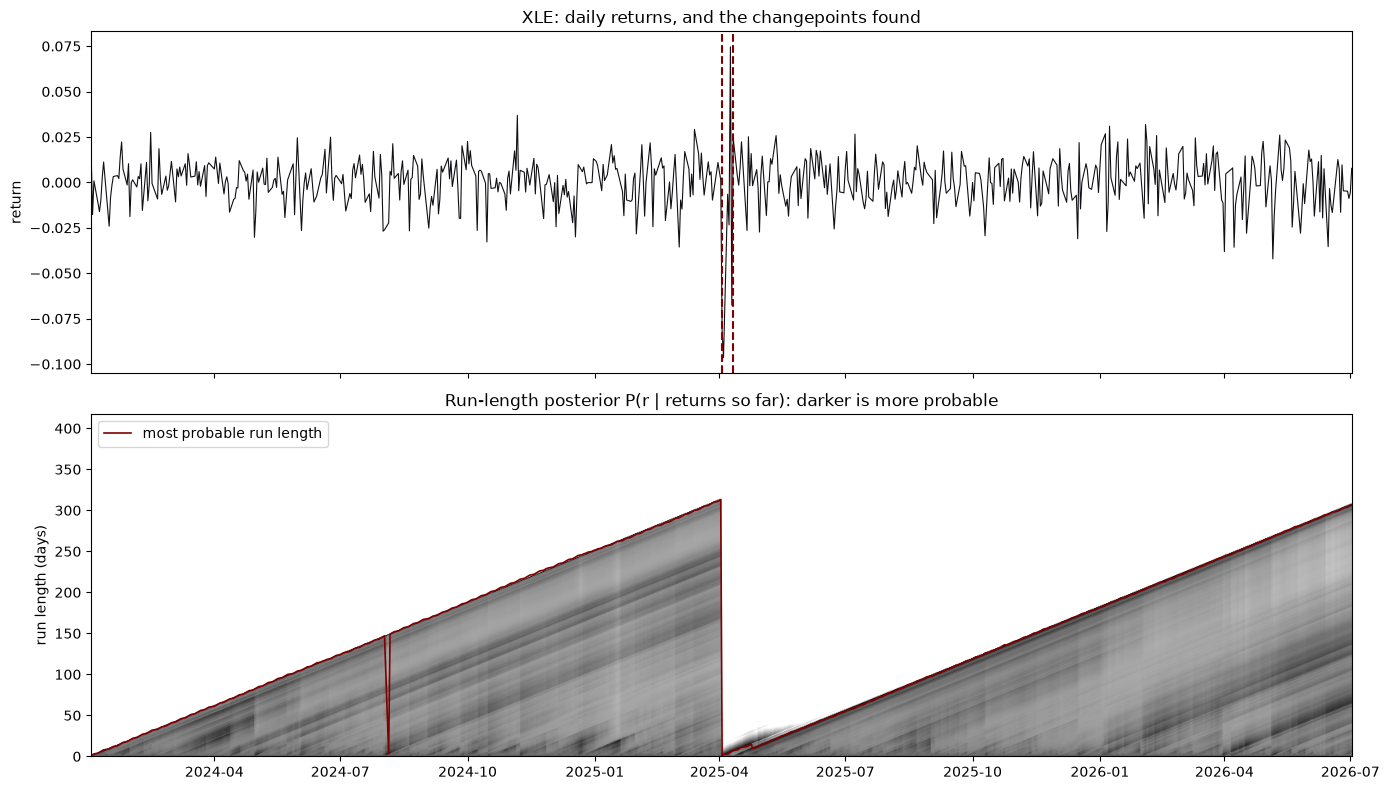

,first day,days,mean return,daily std
0,2024-01-03,313,0.0005,0.0115
1,2025-04-03,6,-0.0335,0.0577
2,2025-04-11,307,0.0012,0.0131


In [6]:
xle = yf.download("XLE", start="2024-01-01", end="2026-07-06", progress=False, auto_adjust=True)["Close"].squeeze().dropna()
y = np.diff(np.log(xle.to_numpy()))
show(xle.index[1:].to_numpy(), y, bocpd(y), "XLE")

## Try it

1. Look up what was in the news on the first days of the short, volatile regimes.
2. Change the hazard to `1 / 50` or `1 / 1000`. Do you find more changes or fewer?
3. Change `beta0`, the prior's guess of the variance, to `1e-2`. What goes wrong, and why?
4. Try another ticker, `"SPY"` or `"TSLA"`.